# Reinforcement Learning for Two-Corrector Orbit Correction (NumPy SAC)

Copyright (C) 2026 Hirokazu Maesaka, RIKEN SPring-8 Center. All rights reserved.

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

## Overview

In an accelerator, the beam orbit deviates from the design orbit because of magnet misalignments, field errors,
and injection errors. Steering magnets (*correctors*) apply small angular kicks to bring the orbit back, using
beam position monitors (*BPMs*) as feedback. The standard method measures the **response matrix**, i.e. how the
BPM readings change per unit corrector kick, and inverts it.

In this notebook we pose the same task as a **reinforcement learning (RL)** problem: an *agent* repeatedly reads
the BPMs, changes the corrector kicks, and receives a *reward* when the orbit improves. The agent is never told
the optics or the incoming beam error; it must learn a correction strategy from interaction alone.

The toy problem is intentionally small (two correctors, one quadrupole, two BPMs) so that

- the classical solution is known exactly and serves as a reference, and
- every part of the RL algorithm can be written in plain NumPy and inspected line by line.

This notebook rewrites the original example to avoid `gymnasium`, `stable-baselines3`, and `torch`.
We keep the same two-corrector orbit-correction task, but implement a compact **Soft Actor-Critic (SAC)** style learner with:

- NumPy for simulation, replay buffer, policy, and learning updates
- SciPy linear algebra for stable critic fitting
- Matplotlib for diagnostics and plots

## Notebook outline

1. Linear-optics simulator of the toy beamline
2. Controllability check of the response matrix
3. RL environment: state, action, and reward
4. Classical response-matrix baseline
5. SAC components: critics, policy, replay buffer, and warm start
6. Training loop
7. Evaluation: single seed, five seeds, and an example trajectory
8. Discussion, limitations, and exercises

## Learning goals

After working through this notebook you should be able to:

- Formulate orbit correction as a Markov decision process (state, action, reward, episode).
- Explain why the response-matrix method solves this toy problem in one step, and what an RL agent must learn instead.
- Describe the building blocks of SAC: replay buffer, twin critics, target critics, stochastic policy, and entropy weight.
- Read a minimal NumPy implementation of these blocks and identify where it simplifies the full algorithm.
- Evaluate a learned controller with success rate and error statistics, and recognize the limits of such evaluations.

**Prerequisites:** linear transfer matrices in beam optics, basic linear algebra, and an introductory picture of RL
(agent, environment, reward).

## Setup

All random numbers derive from a single seed so that the notebook is reproducible.
The seed and most hyperparameters can be overridden by environment variables without editing the code.
For example, in Colab run `%env SEED=29` in a cell before executing the notebook from the top.

In [1]:
from __future__ import annotations

import os
from dataclasses import dataclass
from typing import Final

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg

def env_float(name: str, default: float) -> float:
    """Return float environment override or default."""
    raw_value = os.getenv(name)
    if raw_value is None:
        return default
    return float(raw_value)


def env_int(name: str, default: int) -> int:
    """Return int environment override or default."""
    raw_value = os.getenv(name)
    if raw_value is None:
        return default
    return int(raw_value)


DEFAULT_SEED: Final = 17
SEED: Final = env_int("SEED", DEFAULT_SEED)
RNG = np.random.default_rng(SEED)

print(f"NumPy: {np.__version__}")
print(f"SciPy: {__import__('scipy').__version__}")
print(f"Seed: {SEED}")

NumPy: 2.4.6
SciPy: 1.17.1
Seed: 17


## 1. Linear-optics simulator

We track a single particle in the horizontal plane with the state vector
$$
u = \begin{pmatrix}x \\ x' \end{pmatrix},
$$
where $x$ is the position [m] and $x'$ is the angle [rad]. Each element acts on $u$ as a linear map:

- Drift of length $L$:
$$
D(L)=\begin{pmatrix}1&L\\0&1\end{pmatrix}
$$
- Thin quadrupole of strength $k$:
$$
Q(k)=\begin{pmatrix}1&0\\-k&1\end{pmatrix}
$$
- Steering kick $\theta$:
$$
x' \leftarrow x' + \theta
$$


($k>0$ is focusing.) The beamline order is
`incoming beam -> C1 -> drift -> quad -> drift -> C2 -> drift -> BPM1 -> drift -> BPM2`:

| Element | Position $s$ [m] |
|---|---|
| Corrector C1 | 0.00 |
| Thin quadrupole | 0.60 |
| Corrector C2 | 1.00 |
| BPM1 | 1.70 |
| BPM2 | 2.20 |

**Hidden episode parameters.** At the start of every episode we draw, uniformly at random,

- the incoming offset $x_0 \in [-2, 2]$ mm and angle $x'_0 \in [-1.5, 1.5]$ mrad, and
- the quadrupole strength $k \in [-0.6, 0.6]$ m$^{-1}$.

They represent an unknown injection error and an unknown optics setting (e.g. a mis-set or drifting quadrupole).
The agent never sees them directly; it only sees BPM readings. Because $k$ changes from episode to episode,
no single fixed correction rule derived from one response matrix is exact for all episodes. This is what makes
the problem worth learning.

In [2]:
@dataclass(frozen=True)
class Lattice:
    """Geometry and hidden-latent limits for the two-corrector toy lattice."""

    drift_to_quad: float = 0.60
    drift_to_corrector_2: float = 0.40
    drift_to_bpm_1: float = 0.70
    drift_to_bpm_2: float = 0.50
    x0_limit: float = 2.0e-3
    xp0_limit: float = 1.5e-3
    k_limit: float = 0.60


LATTICE: Final = Lattice()


def drift(length: float) -> np.ndarray:
    """Return the 2x2 drift transfer matrix."""
    return np.array([[1.0, length], [0.0, 1.0]], dtype=np.float64)


def thin_quadrupole(strength: float) -> np.ndarray:
    """Return the 2x2 thin-quadrupole transfer matrix."""
    return np.array([[1.0, 0.0], [-strength, 1.0]], dtype=np.float64)


class BeamlineSimulator:
    """Propagate one horizontal trajectory for fixed hidden episode latents."""

    def __init__(self, lattice: Lattice) -> None:
        self.lattice = lattice
        self.x0 = 0.0
        self.xp0 = 0.0
        self.quadrupole_strength = 0.0

    def set_hidden_episode_state(self, x0: float, xp0: float, quadrupole_strength: float) -> None:
        """Set hidden episode parameters after range validation."""
        if abs(x0) > self.lattice.x0_limit or abs(xp0) > self.lattice.xp0_limit:
            raise ValueError("Incoming coordinates are outside configured limits.")
        if abs(quadrupole_strength) > self.lattice.k_limit:
            raise ValueError("Quadrupole strength is outside configured limits.")
        self.x0 = x0
        self.xp0 = xp0
        self.quadrupole_strength = quadrupole_strength

    def trajectory(self, kicks: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Return longitudinal positions and horizontal orbit along the beamline."""
        if kicks.shape != (2,):
            raise ValueError("Expected exactly two steering kicks.")
        state = np.array([self.x0, self.xp0 + kicks[0]], dtype=np.float64)
        positions = [0.0]
        orbit = [state[0]]

        state = drift(self.lattice.drift_to_quad) @ state
        positions.append(self.lattice.drift_to_quad)
        orbit.append(state[0])

        state = thin_quadrupole(self.quadrupole_strength) @ state
        state = drift(self.lattice.drift_to_corrector_2) @ state
        position_c2 = self.lattice.drift_to_quad + self.lattice.drift_to_corrector_2
        positions.append(position_c2)
        orbit.append(state[0])

        state[1] += kicks[1]
        state = drift(self.lattice.drift_to_bpm_1) @ state
        position_bpm1 = position_c2 + self.lattice.drift_to_bpm_1
        positions.append(position_bpm1)
        orbit.append(state[0])

        state = drift(self.lattice.drift_to_bpm_2) @ state
        positions.append(position_bpm1 + self.lattice.drift_to_bpm_2)
        orbit.append(state[0])
        return np.asarray(positions), np.asarray(orbit)

    def bpm_readings(self, kicks: np.ndarray) -> np.ndarray:
        """Return only BPM1 and BPM2 readings."""
        return self.trajectory(kicks)[1][-2:]

## 2. Controllability check

Because the model is linear, the BPM readings $y=(x_{\mathrm{BPM1}}, x_{\mathrm{BPM2}})^T$ are an affine function
of the kicks $\theta=(\theta_1,\theta_2)^T$:
$$
y(\theta) = y_0 + R(k)\,\theta,
$$
where $y_0$ is the orbit produced by the incoming error $(x_0, x'_0)$ alone and $R(k)$ is the $2\times2$ response matrix.
Writing the drift lengths as $L_1$ (C1 to quad), $L_2$ (quad to C2), $L_3$ (C2 to BPM1), and $L_4$ (BPM1 to BPM2),
the product of the transfer matrices gives
$$
R(k)=
\begin{pmatrix}
L_1 + (L_2+L_3)(1-kL_1) & L_3 \\
L_1 + (L_2+L_3+L_4)(1-kL_1) & L_3+L_4
\end{pmatrix}.
$$

If $R(k)$ is invertible, the kick $\theta^\ast = -R(k)^{-1}y_0$ zeros both BPMs exactly. We scan $k$ over its full
range and check two quantities:

- $\det R$ must stay away from zero, so that a unique solution exists.
- The smallest singular value $\sigma_{\min}$ indicates how much kick is needed in the weakest direction.
  A small $\sigma_{\min}$ means large kicks and high sensitivity to measurement noise.

Minimum |det(R)|: 0.428 m^2/rad^2
Minimum singular value: 0.153 m/rad


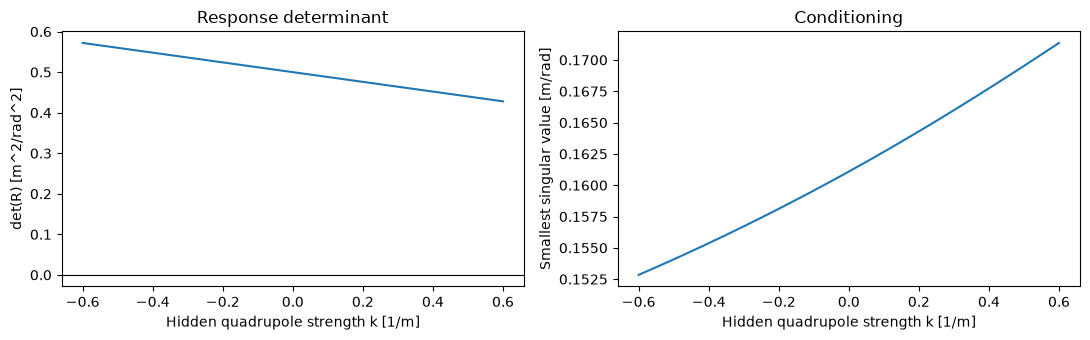

In [3]:
def analytic_response_matrix(quadrupole_strength: float, lattice: Lattice) -> np.ndarray:
    """Return the 2x2 analytic local response matrix."""
    q_transport = 1.0 - quadrupole_strength * lattice.drift_to_quad
    response_11 = lattice.drift_to_quad + (lattice.drift_to_corrector_2 + lattice.drift_to_bpm_1) * q_transport
    response_21 = response_11 + lattice.drift_to_bpm_2 * q_transport
    return np.array(
        [
            [response_11, lattice.drift_to_bpm_1],
            [response_21, lattice.drift_to_bpm_1 + lattice.drift_to_bpm_2],
        ],
        dtype=np.float64,
    )


k_scan = np.linspace(-LATTICE.k_limit, LATTICE.k_limit, 401)
determinants = np.asarray([np.linalg.det(analytic_response_matrix(k_value, LATTICE)) for k_value in k_scan])
smallest_singular_values = np.asarray(
    [np.linalg.svd(analytic_response_matrix(k_value, LATTICE), compute_uv=False)[-1] for k_value in k_scan]
)
assert np.min(np.abs(determinants)) > 0.40
assert np.min(smallest_singular_values) > 0.15
print(f"Minimum |det(R)|: {np.min(np.abs(determinants)):.3f} m^2/rad^2")
print(f"Minimum singular value: {np.min(smallest_singular_values):.3f} m/rad")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_scan, determinants)
axes[0].axhline(0.0, color="black", linewidth=0.8)
axes[0].set(xlabel="Hidden quadrupole strength k [1/m]", ylabel="det(R) [m^2/rad^2]", title="Response determinant")
axes[1].plot(k_scan, smallest_singular_values)
axes[1].set(xlabel="Hidden quadrupole strength k [1/m]", ylabel="Smallest singular value [m/rad]", title="Conditioning")
fig.tight_layout()

## 3. RL environment (without Gym)

RL formalizes control as a **Markov decision process (MDP)**. At each step $t$ the agent observes a state $s_t$,
chooses an action $a_t$, and the environment returns a reward $r_t$ and the next state $s_{t+1}$.
The agent aims to maximize the expected discounted return
$$
G = \sum_{t=0}^{T-1} \gamma^t r_t,\qquad 0<\gamma<1.
$$

We implement the environment as a plain class with `reset()` and `step(action)` methods that mirror the Gym API,
so no external package is needed.

- `reset()` draws new hidden parameters, sets both kicks to zero, and returns the first observation.
- `step(action)` updates the kicks, reads the BPMs, and returns `(observation, reward, done, info)`.
- An episode ends on success or after `MAX_STEPS = 35` steps.

### Observation

The observation includes current normalized BPM readings, BPM differences, previous action, and current kicks:
$$
s_t =
\left(
\frac{x_{\mathrm{BPM1}}}{s_{\mathrm{bpm}}},
\frac{x_{\mathrm{BPM2}}}{s_{\mathrm{bpm}}},
\frac{x_{\mathrm{BPM1},t}-x_{\mathrm{BPM1},t-1}}{s_{\mathrm{bpm}}},
\frac{x_{\mathrm{BPM2},t}-x_{\mathrm{BPM2},t-1}}{s_{\mathrm{bpm}}},
a_{t-1,1},
a_{t-1,2},
\frac{\theta_{t,1}}{\theta_{\max}},
\frac{\theta_{t,2}}{\theta_{\max}}
\right).
$$


Why more than the BPM readings? The current readings alone do not reveal $k$, so the same reading may require
different kicks in different episodes. The state is therefore only *partially observable*. However, the change of
the readings caused by the previous action carries information about the response matrix,
$$
\Delta y_t \approx R(k)\,\Delta\theta_{t-1},
$$
so including $\Delta y$, the previous action, and the current kicks lets the policy infer the response from recent history.
All entries are scaled to order unity ($s_{\mathrm{bpm}} = 1$ mm, $\theta_{\max} = 4$ mrad), which helps the
regression-based learners below.

### Action

The action is a bounded incremental command $a_t\in[-1,1]^2$, mapped to kick increments:
$$
\theta_{t+1} = \mathrm{clip}\left(\theta_t + \Delta\theta_{\max}\,a_t,\ -\theta_{\max},\ \theta_{\max}\right),
\qquad \Delta\theta_{\max} = 0.8\ \mathrm{mrad}.
$$
Incremental actions mimic how operators adjust correctors in small steps and limit how far one bad action can
push the beam. As a consequence, a large initial error usually takes several steps to correct.

### Reward

The reward uses progress shaping:
$$
r_t =
c_{\mathrm{prog}}\left(\|y_t\|_2^2-\|y_{t+1}\|_2^2\right)
-\lambda_a\|a_t\|_2^2
+ r_{\mathrm{milestone}}
+ r_{\mathrm{success}}
+ r_{\mathrm{timeout}},
$$
where $y$ is in units of $s_{\mathrm{bpm}}$, and:

- The **progress term** ($c_{\mathrm{prog}}=0.2$) gives dense feedback at every step. A reward given only on success
  would be *sparse* and much harder to learn from. Summed over an episode it telescopes to roughly
  $c_{\mathrm{prog}}(\|y_0\|^2-\|y_T\|^2)$ for $\gamma\approx1$, so it guides learning without changing which final
  state is best.

  **Why the squared norm?** Since $y_{t+1} = y_t + \Delta\theta_{\max}R(k)\,a_t$ (in normalized units), the squared
  progress term is *quadratic* in the action and can be represented exactly by the quadratic critic features of
  Section 5.2. With the plain norm $\|y\|_2$, the reward has a cone-shaped kink at $y=0$ that a quadratic critic cannot
  fit. In a test with the exploration noise used here, a critic fitted to the norm-based reward had an action
  gradient $\nabla_a Q$ pointing *away* from the true improvement direction (cosine similarity $\approx -0.2$), and
  the actor updates destroyed the warm-start policy within about 100 episodes. With the squared reward the cosine
  similarity was $\approx +0.9$. The scale $0.2$ keeps per-step rewards (initial $\|y_0\|^2$ up to about
  $90\ \mathrm{mm}^2$) within the clipping range of the Bellman targets. This shows that a reward must suit the
  function approximator, not only the task.
- The **action cost** ($\lambda_a = 2\times10^{-3}$) discourages unnecessarily large or oscillating moves.
- $r_{\mathrm{milestone}}$ gives one-time bonuses when the maximum BPM error first crosses predefined thresholds:

  | Threshold of $\max\lvert x_{\mathrm{BPM}}\rvert$ | 100 µm | 50 µm | 20 µm | 10 µm |
  |---|---|---|---|---|
  | Bonus | 0.4 | 0.6 | 0.9 | 1.2 |

  They emphasize the final, fine part of the correction, where the squared progress term becomes tiny.
- $r_{\mathrm{success}} = +5$ is added when $\max\lvert x_{\mathrm{BPM}}\rvert < 10$ µm, which also ends the episode.
- $r_{\mathrm{timeout}} = -1$ is a penalty when the episode ends by step limit without success.

Reward design strongly affects what the agent learns. It is one of the main engineering choices in applied RL.

In [4]:
BPM_SCALE: Final = 1.0e-3
OBSERVATION_CLIP: Final = 6.0
MAX_KICK_INCREMENT: Final = 8.0e-4
MAX_KICK: Final = 4.0e-3
ACTION_COST: Final = 2.0e-3
TARGET_TOLERANCE: Final = 1.0e-5
SUCCESS_BONUS: Final = 5.0
PROGRESS_REWARD_SCALE: Final = 0.2
FAILURE_TERMINAL_PENALTY: Final = 1.0
MILESTONE_THRESHOLDS: Final = np.array([1.0e-4, 5.0e-5, 2.0e-5, 1.0e-5], dtype=np.float64)
MILESTONE_BONUSES: Final = np.array([0.4, 0.6, 0.9, 1.2], dtype=np.float64)
MAX_STEPS: Final = 35


class TwoCorrectorOrbitEnv:
    """Minimal environment API with reset and step methods."""

    def __init__(self, lattice: Lattice, rng_seed: int) -> None:
        self.lattice = lattice
        self.rng = np.random.default_rng(rng_seed)
        self.simulator = BeamlineSimulator(lattice)
        self.kicks = np.zeros(2, dtype=np.float64)
        self.current_normalized_bpm = np.zeros(2, dtype=np.float64)
        self.previous_normalized_bpm = np.zeros(2, dtype=np.float64)
        self.last_action = np.zeros(2, dtype=np.float64)
        self.step_count = 0
        self.previous_squared_error = 0.0
        self.milestone_reached = np.zeros(MILESTONE_THRESHOLDS.size, dtype=bool)

    def _observation(self) -> np.ndarray:
        normalized_bpm = np.clip(self.current_normalized_bpm, -OBSERVATION_CLIP, OBSERVATION_CLIP)
        normalized_bpm_difference = np.clip(
            self.current_normalized_bpm - self.previous_normalized_bpm,
            -OBSERVATION_CLIP,
            OBSERVATION_CLIP,
        )
        normalized_kicks = self.kicks / MAX_KICK
        return np.concatenate([normalized_bpm, normalized_bpm_difference, self.last_action, normalized_kicks])

    def reset(self) -> np.ndarray:
        x0 = self.rng.uniform(-self.lattice.x0_limit, self.lattice.x0_limit)
        xp0 = self.rng.uniform(-self.lattice.xp0_limit, self.lattice.xp0_limit)
        quadrupole_strength = self.rng.uniform(-self.lattice.k_limit, self.lattice.k_limit)
        self.simulator.set_hidden_episode_state(x0, xp0, quadrupole_strength)
        self.kicks.fill(0.0)
        initial_normalized_bpm = self.simulator.bpm_readings(self.kicks) / BPM_SCALE
        self.current_normalized_bpm = initial_normalized_bpm
        self.previous_normalized_bpm = initial_normalized_bpm.copy()
        self.last_action.fill(0.0)
        self.step_count = 0
        self.previous_squared_error = float(np.dot(initial_normalized_bpm, initial_normalized_bpm))
        self.milestone_reached.fill(False)
        return self._observation()

    def step(self, action: np.ndarray) -> tuple[np.ndarray, float, bool, dict]:
        clipped_action = np.clip(np.asarray(action, dtype=np.float64), -1.0, 1.0)
        bpm_before_update = self.current_normalized_bpm.copy()
        self.last_action = clipped_action.copy()
        self.kicks = np.clip(self.kicks + MAX_KICK_INCREMENT * clipped_action, -MAX_KICK, MAX_KICK)
        self.step_count += 1
        readings = self.simulator.bpm_readings(self.kicks)
        normalized = readings / BPM_SCALE
        self.previous_normalized_bpm = bpm_before_update
        self.current_normalized_bpm = normalized
        current_squared_error = float(np.dot(normalized, normalized))
        progress_reward = PROGRESS_REWARD_SCALE * (self.previous_squared_error - current_squared_error)
        is_success = bool(np.max(np.abs(readings)) < TARGET_TOLERANCE)
        reward = progress_reward - ACTION_COST * float(np.dot(clipped_action, clipped_action))
        max_abs_reading = float(np.max(np.abs(readings)))
        for milestone_index, threshold in enumerate(MILESTONE_THRESHOLDS):
            if (not self.milestone_reached[milestone_index]) and max_abs_reading < threshold:
                reward += float(MILESTONE_BONUSES[milestone_index])
                self.milestone_reached[milestone_index] = True
        if is_success:
            reward += SUCCESS_BONUS
        timed_out = self.step_count >= MAX_STEPS
        if timed_out and not is_success:
            reward -= FAILURE_TERMINAL_PENALTY
        done = bool(is_success or timed_out)
        self.previous_squared_error = current_squared_error
        info = {"is_success": is_success, "max_abs_reading": max_abs_reading}
        return self._observation(), reward, done, info


env_probe = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED)
observation = env_probe.reset()
print("Initial observation [BPM, BPM difference, previous action, normalized kicks]:", observation)
assert observation.shape == (8,)

Initial observation [BPM, BPM difference, previous action, normalized kicks]: [-0.40743349 -0.94265359  0.          0.          0.          0.
  0.          0.        ]


## 4. Response-matrix baseline

The classical method first measures $R$ by probing each corrector around the current operating point:
$$
R_{:,j}\approx\frac{y(\theta+\delta e_j)-y(\theta-\delta e_j)}{2\delta},
$$
where $e_j$ is the unit vector for corrector $j$ and $\delta = 1$ µrad. It then applies one linear correction:
$$
\Delta\theta = -R^{-1}y.
$$

Because the model is linear and noiseless, a single correction reaches the target down to numerical round-off.
This is the reference: **in this idealized setting RL cannot beat the response-matrix method.** Note, however,
that the baseline needs four extra probe measurements per episode (since $k$ changes), whereas the RL agent uses
only its observations. The purpose of the exercise is the methodology. Learning a controller without a model
becomes attractive when the machine is nonlinear, noisy, or drifting, or when measuring $R$ is expensive.

In [5]:
RESPONSE_PROBE: Final = 1.0e-6


def estimate_response_matrix(simulator: BeamlineSimulator, kicks: np.ndarray, probe: float = RESPONSE_PROBE) -> np.ndarray:
    """Estimate the local 2x2 response matrix from symmetric kick probes."""
    response = np.empty((2, 2), dtype=np.float64)
    for column in range(2):
        positive = kicks.copy()
        negative = kicks.copy()
        positive[column] += probe
        negative[column] -= probe
        response[:, column] = (simulator.bpm_readings(positive) - simulator.bpm_readings(negative)) / (2.0 * probe)
    return response


def response_matrix_correction(environment: TwoCorrectorOrbitEnv) -> tuple[np.ndarray, np.ndarray]:
    """Apply one local response-matrix correction and return before/after BPM readings."""
    before = environment.simulator.bpm_readings(environment.kicks)
    response = estimate_response_matrix(environment.simulator, environment.kicks)
    kick_change = np.linalg.solve(response, -before)
    environment.kicks = np.clip(environment.kicks + kick_change, -MAX_KICK, MAX_KICK)
    after = environment.simulator.bpm_readings(environment.kicks)
    return before, after


baseline_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 1)
baseline_env.reset()
baseline_before, baseline_after = response_matrix_correction(baseline_env)
print("Baseline before [mm]:", 1.0e3 * baseline_before)
print("Baseline after [um]:", 1.0e6 * baseline_after)

Baseline before [mm]: [0.70273095 1.02734979]
Baseline after [um]: [2.10419346e-11 2.84958245e-11]


## 5. NumPy SAC components

### 5.1 Background: Soft Actor-Critic

SAC (Haarnoja et al., 2018) is an off-policy actor-critic algorithm for continuous actions.
It maximizes the return plus the entropy $\mathcal{H}$ of the policy,
$$
J(\pi) = \mathbb{E}\left[\sum_t \gamma^t\left(r_t + \alpha\,\mathcal{H}\big(\pi(\cdot|s_t)\big)\right)\right],
$$
so that the agent keeps exploring while it improves. The entropy weight $\alpha$ sets the trade-off.
Its main ingredients are:

| Component | Role |
|---|---|
| Replay buffer | Stores past transitions $(s, a, r, s', \mathrm{done})$ so that data can be reused (off-policy learning). |
| Twin critics $Q_{\theta_1}, Q_{\theta_2}$ | Estimate the expected return of action $a$ in state $s$; the minimum of the two reduces overestimation bias. |
| Target critics $Q_{\bar\theta_i}$ | Slowly moving copies (Polyak averaging) used in the Bellman target, which stabilizes learning. |
| Stochastic policy (actor) | Gaussian $\pi_\phi(a|s)=\mathcal{N}(\mu_\phi(s),\mathrm{diag}(\sigma_\phi^2))$, squashed by $\tanh$ into $[-1,1]$. |
| Entropy weight $\alpha$ | Tuned automatically so that the policy entropy stays near a target value. |

Critic target:
$$
y=r+\gamma\left(\min_i Q_{\bar\theta_i}(s',a')-\alpha\log\pi_\phi(a'|s')\right)
$$

Actor objective:
$$
J(\phi)=\mathbb{E}_{s,a\sim\pi_\phi}\left[\alpha\log\pi_\phi(a|s)-\min_i Q_{\theta_i}(s,a)\right].
$$

### 5.2 Simplifications in this notebook

A full SAC uses deep neural networks trained by automatic differentiation. To stay NumPy-only we simplify:

1. **Linear critic on hand-crafted features.** $Q(s,a) = w^T\varphi(s,a)$ with
   $$
   \varphi(s,a) = \left[1,\ s,\ a,\ s\otimes a,\ a^2,\ s^2\right]
   $$
   (37 features for the 8-dimensional $s$ and 2-dimensional $a$). On each mini-batch with feature matrix $\Phi$ and
   Bellman targets $y$, the weights are moved toward the ridge-regression solution:
   $$
   w^\ast = (\Phi^T\Phi + \lambda I)^{-1}\Phi^T y,\qquad w \leftarrow (1-\beta)\,w + \beta\,w^\ast,
   $$
   with $\lambda$ = `CRITIC_RIDGE` and $\beta$ = `CRITIC_MIX`. Because $Q$ is quadratic in $a$, its action gradient
   $\nabla_a Q$ is available in closed form.
2. **Residual, bias-free policy mean.** A linear part plus a one-hidden-layer $\tanh$ network acting on the policy input
   $z = (y/s_{\mathrm{bpm}},\ \Delta y/s_{\mathrm{bpm}},\ a_{t-1})$, i.e. the first six observation entries:
   $$
   \mu_\phi(s) = W_{\mathrm{lin}}z + W_{\mathrm{out}}\tanh(W_{\mathrm{h}}z),
   \qquad a = \tanh\left(\mu_\phi(s) + \sigma\,\epsilon\right),\quad \epsilon\sim\mathcal{N}(0, I).
   $$
   The linear part can express a response-matrix-like correction, and the network adds nonlinear refinements.

   **Why no bias and no absolute kicks?** Because the action is a kick *increment*, the closed loop acts as an
   integral controller: the kicks stop moving only where the mean action is zero. At the target orbit, $z = 0$,
   so a bias-free $\mu_\phi$ gives exactly $\mu_\phi = 0$ there. A bias term, or a weight on the absolute kicks
   (whose correct value differs from episode to episode), would instead keep pushing the kicks at the target and
   leave a steady-state orbit offset of tens of micrometres. The critic still sees the full observation.
   This is an example of building physical knowledge into the model structure (an *inductive bias*).
3. **Pathwise actor update.** Since $a$ is a differentiable function of $\phi$ for fixed noise $\epsilon$
   (the reparameterization trick), we use a pathwise-style deterministic policy update based on critic action gradients:
   $$
   \nabla_\phi J
   \approx
   \mathbb{E}\left[\nabla_a Q_{\min}(s,a)\,\nabla_\phi a_\phi(s,\epsilon)\right].
   $$
   The chain rule through $\tanh$ ($\partial a/\partial u = 1-a^2$) and through $\mu_\phi$ is written out by hand
   in `update_with_action_gradient`, followed by one gradient-*ascent* step.
   This keeps the implementation compact and avoids external autodiff libraries.
4. **Fixed exploration noise.** The entropy term $\alpha\log\pi$ is omitted from the actor gradient, and
   $\log\sigma$ is not learned; it is only kept within $[-2, -0.8]$ (and set to $-1.6$ after the warm start).
   Hence $\alpha$ enters only through the critic target, and the automatic $\alpha$ tuning cannot change the
   policy entropy. In practice $\alpha$ tends to drift to its upper bound `ALPHA_MAX`.
   For these reasons the method is "SAC-style" rather than exact SAC.
5. **Parameter clipping.** All policy weights are clipped to fixed ranges after each update. This is a crude
   safeguard against divergence, standing in for the gradient clipping and normalization used in deep RL libraries.

### 5.3 Warm start from the response-matrix oracle (behavior cloning)

Learning from scratch with such simple approximators is sample-inefficient. We therefore first collect
oracle pairs $(s_0, u^\ast)$ at the start of random episodes, with the unclipped normalized kick change
$$
u^\ast = -\frac{R^{-1}y_0}{\Delta\theta_{\max}},
$$
and fit the linear part of the policy, $W_{\mathrm{lin}}z \approx u^\ast$, by ridge regression without intercept.
Fitting the pre-$\tanh$ mean to the unclipped $u^\ast$ lets $\tanh$ saturate large corrections naturally, whereas
fitting $\operatorname{arctanh}$ of clipped actions would turn the many saturated samples into huge, distorted targets.
The output layer of the network is set to zero, so the network starts as an exact zero residual while its random
hidden layer keeps nonzero gradients for later fine-tuning.

This is *behavior cloning* (imitation learning); RL then fine-tunes the cloned policy. The warm start is not exact:

- All oracle states are episode starts, where the BPM differences and previous action are zero,
  so the weights on those inputs are constrained only by the ridge penalty.
- Since $R$ depends on the hidden $k$, a linear function of $z$ cannot reproduce the oracle exactly.
  Repeated application still converges, because the closed-loop map $I + \Delta\theta_{\max}R(k)W_{\mathrm{lin}}/s_{\mathrm{bpm}}$
  is contracting over the whole $k$ range.

### 5.4 Evaluation helper

`evaluate_policy_success` runs the deterministic policy $a=\tanh(\mu_\phi(s))$ on fresh episodes and returns the
mean return, the success rate, and the median final $\max\lvert x_{\mathrm{BPM}}\rvert$.

In [6]:
def critic_features(states: np.ndarray, actions: np.ndarray) -> np.ndarray:
    """Create polynomial features for linear Q approximators."""
    if actions.shape[1] != 2:
        raise ValueError("This implementation expects exactly two actions.")
    cross_terms = (states[:, :, None] * actions[:, None, :]).reshape(states.shape[0], -1)
    action_squares = actions**2
    state_squares = states**2
    return np.concatenate(
        [
            np.ones((states.shape[0], 1), dtype=np.float64),
            states,
            actions,
            cross_terms,
            action_squares,
            state_squares,
        ],
        axis=1,
    )


def critic_feature_dim(state_dim: int, action_dim: int) -> int:
    """Return feature size used by critic_features."""
    return 1 + state_dim + action_dim + state_dim * action_dim + action_dim + state_dim


@dataclass
class ReplayBuffer:
    """Fixed-size replay buffer for off-policy updates."""

    states: np.ndarray
    actions: np.ndarray
    rewards: np.ndarray
    next_states: np.ndarray
    dones: np.ndarray
    size: int = 0
    pointer: int = 0

    @classmethod
    def create(cls, capacity: int, state_dim: int, action_dim: int) -> "ReplayBuffer":
        return cls(
            states=np.zeros((capacity, state_dim), dtype=np.float64),
            actions=np.zeros((capacity, action_dim), dtype=np.float64),
            rewards=np.zeros(capacity, dtype=np.float64),
            next_states=np.zeros((capacity, state_dim), dtype=np.float64),
            dones=np.zeros(capacity, dtype=np.float64),
        )

    @property
    def capacity(self) -> int:
        return self.states.shape[0]

    def add(self, state: np.ndarray, action: np.ndarray, reward: float, next_state: np.ndarray, done: bool) -> None:
        self.states[self.pointer] = state
        self.actions[self.pointer] = action
        self.rewards[self.pointer] = reward
        self.next_states[self.pointer] = next_state
        self.dones[self.pointer] = float(done)
        self.pointer = (self.pointer + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size: int, rng: np.random.Generator) -> tuple[np.ndarray, ...]:
        if self.size < batch_size:
            raise ValueError("Not enough samples in replay buffer.")
        indices = rng.integers(0, self.size, size=batch_size)
        return (
            self.states[indices],
            self.actions[indices],
            self.rewards[indices],
            self.next_states[indices],
            self.dones[indices],
        )


@dataclass
class LinearCritic:
    """Linear Q approximator fitted by regularized least squares on each batch."""

    weights: np.ndarray

    @classmethod
    def create(cls, feature_dim: int, rng: np.random.Generator) -> "LinearCritic":
        return cls(weights=0.01 * rng.standard_normal(feature_dim))

    def predict(self, states: np.ndarray, actions: np.ndarray) -> np.ndarray:
        features = critic_features(states, actions)
        return features @ self.weights

    def action_gradient(self, states: np.ndarray, actions: np.ndarray) -> np.ndarray:
        """Return dQ/da for each state-action pair."""
        state_dim = states.shape[1]
        action_dim = actions.shape[1]
        if action_dim != 2:
            raise ValueError("This implementation expects exactly two actions.")

        action_start = 1 + state_dim
        cross_start = action_start + action_dim
        action_square_start = cross_start + state_dim * action_dim

        gradients = np.zeros_like(actions)
        for action_index in range(action_dim):
            gradients[:, action_index] += self.weights[action_start + action_index]
            cross_weights = self.weights[cross_start + action_index : cross_start + state_dim * action_dim : action_dim]
            gradients[:, action_index] += states @ cross_weights
            gradients[:, action_index] += 2.0 * self.weights[action_square_start + action_index] * actions[:, action_index]
        return gradients

    def fit_batch(self, states: np.ndarray, actions: np.ndarray, targets: np.ndarray, ridge: float, mix: float) -> None:
        features = critic_features(states, actions)
        if not (np.all(np.isfinite(features)) and np.all(np.isfinite(targets))):
            return
        gram = features.T @ features
        regularized = gram + ridge * np.eye(gram.shape[0], dtype=np.float64)
        rhs = features.T @ targets
        solved = scipy.linalg.solve(regularized, rhs, assume_a="pos")
        self.weights = (1.0 - mix) * self.weights + mix * solved


POLICY_INPUT_DIM: Final = 6
PolicySnapshot = tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]


@dataclass
class GaussianPolicy:
    """Residual one-hidden-layer squashed Gaussian policy without bias terms.

    The policy reads only the first `POLICY_INPUT_DIM` observation entries (BPM readings, BPM differences, and
    previous action). All of them vanish at a perfectly corrected orbit, and no layer has a bias, so the mean action
    is exactly zero there. This keeps the incremental controller free of steady-state offsets.
    """

    linear_weight: np.ndarray
    hidden_weight: np.ndarray
    output_weight: np.ndarray
    log_std: np.ndarray

    @classmethod
    def create(
        cls,
        input_dim: int,
        action_dim: int,
        hidden_dim: int,
        rng: np.random.Generator,
    ) -> "GaussianPolicy":
        return cls(
            linear_weight=np.zeros((action_dim, input_dim), dtype=np.float64),
            hidden_weight=0.02 * rng.standard_normal((hidden_dim, input_dim)),
            output_weight=0.02 * rng.standard_normal((action_dim, hidden_dim)),
            log_std=np.full(action_dim, -1.2, dtype=np.float64),
        )

    def _inputs(self, states: np.ndarray) -> np.ndarray:
        """Select the policy inputs from full observations."""
        return states[:, : self.linear_weight.shape[1]]

    def _hidden(self, inputs: np.ndarray) -> np.ndarray:
        return np.tanh(inputs @ self.hidden_weight.T)

    def mean(self, states: np.ndarray) -> np.ndarray:
        inputs = self._inputs(states)
        linear_component = inputs @ self.linear_weight.T
        nonlinear_component = self._hidden(inputs) @ self.output_weight.T
        return linear_component + nonlinear_component

    def _squash(self, pre_tanh_actions: np.ndarray) -> np.ndarray:
        return np.tanh(pre_tanh_actions)

    def deterministic_actions(self, states: np.ndarray) -> np.ndarray:
        """Return deterministic bounded actions for a batch of states."""
        return self._squash(self.mean(states))

    def sample(self, states: np.ndarray, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
        mean_values = self.mean(states)
        std = np.exp(self.log_std)
        noise = rng.standard_normal(mean_values.shape)
        pre_tanh_actions = mean_values + noise * std
        actions = self._squash(pre_tanh_actions)
        log_prob = self.log_prob(states, actions, pre_tanh_actions=pre_tanh_actions)
        return actions, log_prob

    def deterministic_action(self, state: np.ndarray) -> np.ndarray:
        return self.deterministic_actions(state[None, :])[0]

    def log_prob(
        self,
        states: np.ndarray,
        actions: np.ndarray,
        pre_tanh_actions: np.ndarray | None = None,
    ) -> np.ndarray:
        mean_values = self.mean(states)
        std = np.exp(self.log_std)
        if pre_tanh_actions is None:
            clipped_actions = np.clip(actions, -0.999999, 0.999999)
            pre_tanh_actions = np.arctanh(clipped_actions)
        normalized = np.clip((pre_tanh_actions - mean_values) / std, -20.0, 20.0)
        dimension = actions.shape[1]
        gaussian_log_prob = -0.5 * (
            np.sum(normalized**2, axis=1)
            + 2.0 * np.sum(self.log_std)
            + dimension * np.log(2.0 * np.pi)
        )
        squash_correction = np.sum(np.log(1.0 - np.clip(actions**2, 0.0, 0.999999) + 1.0e-6), axis=1)
        log_prob = gaussian_log_prob - squash_correction
        return np.clip(log_prob, -80.0, 40.0)

    def update_with_action_gradient(
        self,
        states: np.ndarray,
        pre_tanh_actions: np.ndarray,
        action_gradient: np.ndarray,
        learning_rate: float,
    ) -> None:
        actions = self._squash(pre_tanh_actions)
        tanh_derivative = 1.0 - actions**2
        effective_action_gradient = np.clip(action_gradient * tanh_derivative, -20.0, 20.0)
        inputs = self._inputs(states)
        hidden = self._hidden(inputs)
        grad_linear_weight = effective_action_gradient.T @ inputs
        grad_output_weight = effective_action_gradient.T @ hidden
        hidden_gradient = effective_action_gradient @ self.output_weight
        hidden_pre_gradient = hidden_gradient * (1.0 - hidden**2)
        grad_hidden_weight = hidden_pre_gradient.T @ inputs
        scale = 1.0 / states.shape[0]
        self.linear_weight += learning_rate * scale * grad_linear_weight
        self.output_weight += learning_rate * scale * grad_output_weight
        self.hidden_weight += learning_rate * scale * grad_hidden_weight
        self.linear_weight = np.clip(self.linear_weight, -3.5, 3.5)
        self.hidden_weight = np.clip(self.hidden_weight, -2.5, 2.5)
        self.output_weight = np.clip(self.output_weight, -2.5, 2.5)
        self.log_std = np.clip(self.log_std, -2.0, -0.8)

    def snapshot(self) -> PolicySnapshot:
        """Return a deep-copied parameter snapshot."""
        return (
            self.linear_weight.copy(),
            self.hidden_weight.copy(),
            self.output_weight.copy(),
            self.log_std.copy(),
        )

    def restore(self, snapshot: PolicySnapshot) -> None:
        """Restore policy parameters from a snapshot."""
        (
            self.linear_weight,
            self.hidden_weight,
            self.output_weight,
            self.log_std,
        ) = [parameter.copy() for parameter in snapshot]


def build_oracle_dataset(
    lattice: Lattice,
    sample_count: int,
    rng_seed: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Build states and unclipped normalized kick changes from one-step response-matrix corrections."""
    environment = TwoCorrectorOrbitEnv(lattice, rng_seed=rng_seed)
    state_dim = environment.reset().shape[0]
    states = np.zeros((sample_count, state_dim), dtype=np.float64)
    kick_ratios = np.zeros((sample_count, 2), dtype=np.float64)
    for index in range(sample_count):
        state = environment.reset()
        before = environment.simulator.bpm_readings(environment.kicks)
        response = estimate_response_matrix(environment.simulator, environment.kicks)
        kick_change = np.linalg.solve(response, -before)
        states[index] = state
        kick_ratios[index] = kick_change / MAX_KICK_INCREMENT
    return states, kick_ratios


def warmstart_policy_from_oracle(
    policy: GaussianPolicy,
    states: np.ndarray,
    kick_ratios: np.ndarray,
    ridge: float,
) -> None:
    """Fit the linear policy part to unclipped oracle kick ratios by ridge regression without intercept."""
    inputs = states[:, :POLICY_INPUT_DIM]
    regularized = inputs.T @ inputs + ridge * np.eye(inputs.shape[1], dtype=np.float64)
    solved = scipy.linalg.solve(regularized, inputs.T @ kick_ratios, assume_a="pos")
    policy.linear_weight = solved.T
    # Zero only the output layer: the network starts as an exact residual of zero, while the random hidden layer
    # keeps nonzero gradients for both layers.
    policy.output_weight *= 0.0


@dataclass(frozen=True)
class EvaluationSummary:
    """Aggregate deterministic-policy metrics over evaluation episodes."""

    mean_return: float
    success_rate: float
    median_error_um: float
    mean_steps: float


def evaluate_policy_success(
    policy: GaussianPolicy,
    lattice: Lattice,
    rng_seed: int,
    episodes: int,
) -> EvaluationSummary:
    """Return mean return, success rate, median final max BPM error [um], and mean episode length."""
    environment = TwoCorrectorOrbitEnv(lattice, rng_seed=rng_seed)
    returns: list[float] = []
    final_errors: list[float] = []
    episode_lengths: list[int] = []
    successes = 0
    for _ in range(episodes):
        state = environment.reset()
        done = False
        episode_return = 0.0
        info = {"is_success": False}
        while not done:
            action = policy.deterministic_action(state)
            state, reward, done, info = environment.step(action)
            episode_return += reward
        final_bpm = environment.simulator.bpm_readings(environment.kicks)
        final_max_error = float(np.max(np.abs(final_bpm)))
        returns.append(episode_return)
        final_errors.append(final_max_error)
        episode_lengths.append(environment.step_count)
        successes += int(info["is_success"])
    return EvaluationSummary(
        mean_return=float(np.mean(returns)),
        success_rate=100.0 * successes / episodes,
        median_error_um=1.0e6 * float(np.median(final_errors)),
        mean_steps=float(np.mean(episode_lengths)),
    )

## 6. Training loop

Each episode has up to 35 steps and ends early on success. Learning is off-policy: every environment step adds one
transition to the replay buffer, and the learners are updated from random mini-batches of past transitions.
The procedure is:

1. Warm-start the policy from the oracle dataset (Section 5.3) and set $\sigma = e^{-1.6}$.
2. At every environment step:
   1. **Act.** Use uniformly random actions during the first `WARMUP_STEPS` steps to fill the buffer;
      afterwards sample $a\sim\pi_\phi(\cdot|s)$.
   2. **Store** $(s, a, r, s', \mathrm{done})$ in the replay buffer.
   3. **Update** on a mini-batch of `BATCH_SIZE` transitions:
      - Compute Bellman targets with the target critics and next actions $a'\sim\pi_\phi(\cdot|s')$,
        clipped to $[-300, 20]$ for numerical safety.
      - Refit both critics (ridge regression with partial mixing).
      - Take one actor step along $\nabla_a Q_{\min}$ (the critic with the smaller value per sample).
      - Update the entropy weight with $\log\alpha \leftarrow \log\alpha + \eta_\alpha(\bar{\mathcal{H}} - \hat{\mathcal{H}})$,
        where $\hat{\mathcal{H}} = -\overline{\log\pi}$ is the batch entropy estimate and $\bar{\mathcal{H}}$ the target,
        then clip $\alpha$ to $[\alpha_{\min}, \alpha_{\max}]$.
      - Polyak-average the target critics: $\bar w \leftarrow \tau\bar w + (1-\tau)w$ with $\tau$ = `POLYAK`.
3. Every `EVALUATION_INTERVAL_EPISODES` episodes, evaluate the deterministic policy on 80 fresh episodes and keep the
   best snapshot (highest success rate, ties broken by the mean number of steps per episode). Stop early after
   `EARLY_STOPPING_PATIENCE_EVALS` evaluations without improvement.
4. Restore the best snapshot.

**Why keep the best snapshot?** RL with function approximation is often non-monotonic: a policy can improve and then
degrade as the critic estimates shift. Checkpoint selection on validation episodes is common practice, but the final
performance then partly reflects this selection. Validation and final evaluation therefore use different random seeds.

**Note on the twin critics.** Here both critics are fitted to the same targets on the same batch, so they become
nearly identical after a few updates and the minimum has little effect. In full SAC they are separately initialized
networks trained by stochastic gradients, so they stay distinct.

Recommended fixed configuration (after multi-seed checks):

| Parameter | Value | Meaning |
|---|---|---|
| `POLICY_HIDDEN_DIM` | 16 | Hidden units of the residual policy network |
| `ACTOR_LR` | $2.0\times10^{-5}$ | Actor learning rate |
| `CRITIC_MIX` | 0.12 | Fraction $\beta$ of the new ridge solution mixed into the critic weights |
| `CRITIC_RIDGE` | $5.0\times10^{-3}$ | Ridge penalty $\lambda$ of the critic fit |
| `GAMMA` | 0.98 | Discount factor $\gamma$ |
| `POLYAK` | 0.99 | Target-critic averaging factor $\tau$ |
| `ALPHA_MAX` | 0.08 | Upper bound of the entropy weight $\alpha$ |
| `TARGET_POLICY_ENTROPY` | 0.4 | Target entropy $\bar{\mathcal{H}}$ |
| `EVALUATION_INTERVAL_EPISODES` | 25 | Episodes between validation runs |
| `EARLY_STOPPING_PATIENCE_EVALS` | 10 | Validation runs without improvement before stopping |

Every value can be overridden by an environment variable of the same name, and `SEED` controls reproducibility.

In [7]:
GAMMA: Final = env_float("GAMMA", 0.98)
INITIAL_ALPHA: Final = env_float("INITIAL_ALPHA", 0.05)
TARGET_POLICY_ENTROPY: Final = env_float("TARGET_POLICY_ENTROPY", 0.4)
ALPHA_LR: Final = env_float("ALPHA_LR", 4.0e-4)
ALPHA_MIN: Final = env_float("ALPHA_MIN", 5.0e-3)
ALPHA_MAX: Final = env_float("ALPHA_MAX", 0.08)
BATCH_SIZE: Final = env_int("BATCH_SIZE", 256)
BUFFER_CAPACITY: Final = env_int("BUFFER_CAPACITY", 60_000)
WARMUP_STEPS: Final = env_int("WARMUP_STEPS", 1_000)
TRAIN_EPISODES: Final = env_int("TRAIN_EPISODES", 700)
UPDATES_PER_STEP: Final = env_int("UPDATES_PER_STEP", 1)
POLYAK: Final = env_float("POLYAK", 0.99)
CRITIC_RIDGE: Final = env_float("CRITIC_RIDGE", 5.0e-3)
CRITIC_MIX: Final = env_float("CRITIC_MIX", 0.12)
ACTOR_LR: Final = env_float("ACTOR_LR", 2.0e-5)
ORACLE_WARMSTART_SAMPLES: Final = env_int("ORACLE_WARMSTART_SAMPLES", 8_000)
ORACLE_WARMSTART_RIDGE: Final = env_float("ORACLE_WARMSTART_RIDGE", 1.0e-3)
POLICY_HIDDEN_DIM: Final = env_int("POLICY_HIDDEN_DIM", 16)
EARLY_STOPPING_PATIENCE_EVALS: Final = env_int("EARLY_STOPPING_PATIENCE_EVALS", 10)
EVALUATION_INTERVAL_EPISODES: Final = env_int("EVALUATION_INTERVAL_EPISODES", 25)

print(
    "Training config:",
    f"ACTOR_LR={ACTOR_LR:.2e},",
    f"CRITIC_MIX={CRITIC_MIX:.3f},",
    f"CRITIC_RIDGE={CRITIC_RIDGE:.2e},",
    f"HIDDEN_DIM={POLICY_HIDDEN_DIM},",
    f"ALPHA_MAX={ALPHA_MAX:.3f},",
    f"TARGET_POLICY_ENTROPY={TARGET_POLICY_ENTROPY:.3f}",
)

training_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 10)
evaluation_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=SEED + 20)
state_dim = training_env.reset().shape[0]
action_dim = 2
feature_dim = critic_feature_dim(state_dim=state_dim, action_dim=action_dim)
policy = GaussianPolicy.create(
    input_dim=POLICY_INPUT_DIM,
    action_dim=action_dim,
    hidden_dim=POLICY_HIDDEN_DIM,
    rng=RNG,
)
critic_1 = LinearCritic.create(feature_dim=feature_dim, rng=RNG)
critic_2 = LinearCritic.create(feature_dim=feature_dim, rng=RNG)
target_critic_1 = LinearCritic(weights=critic_1.weights.copy())
target_critic_2 = LinearCritic(weights=critic_2.weights.copy())
replay = ReplayBuffer.create(capacity=BUFFER_CAPACITY, state_dim=state_dim, action_dim=action_dim)

warmstart_states, warmstart_kick_ratios = build_oracle_dataset(
    lattice=LATTICE,
    sample_count=ORACLE_WARMSTART_SAMPLES,
    rng_seed=SEED + 123,
)
warmstart_policy_from_oracle(
    policy=policy,
    states=warmstart_states,
    kick_ratios=warmstart_kick_ratios,
    ridge=ORACLE_WARMSTART_RIDGE,
)
policy.log_std[:] = -1.6
print("Initialized policy from one-step response-matrix oracle dataset.")
warmstart_summary = evaluate_policy_success(
    policy=policy,
    lattice=LATTICE,
    rng_seed=SEED + 220,
    episodes=120,
)
print(
    "Warm-start policy:",
    f"mean return={warmstart_summary.mean_return:.2f},",
    f"success={warmstart_summary.success_rate:.1f}%,",
    f"mean steps={warmstart_summary.mean_steps:.2f},",
    f"median error={warmstart_summary.median_error_um:.1f} um",
)

best_policy_snapshot = policy.snapshot()
best_summary = warmstart_summary
log_alpha = float(np.log(INITIAL_ALPHA))
current_alpha = INITIAL_ALPHA
evaluations_without_improvement = 0
completed_episodes = 0

episode_returns: list[float] = []
total_steps = 0
for episode in range(TRAIN_EPISODES):
    state = training_env.reset()
    cumulative_reward = 0.0
    done = False
    while not done:
        if total_steps < WARMUP_STEPS:
            raw_action = RNG.uniform(-1.0, 1.0, size=2)
        else:
            sampled_action, _ = policy.sample(state[None, :], RNG)
            raw_action = sampled_action[0]

        action = np.clip(raw_action, -1.0, 1.0)
        next_state, reward, done, _ = training_env.step(action)
        replay.add(state, action, reward, next_state, done)
        state = next_state
        cumulative_reward += reward
        total_steps += 1

        if replay.size >= BATCH_SIZE and total_steps >= WARMUP_STEPS:
            for _ in range(UPDATES_PER_STEP):
                batch_states, batch_actions, batch_rewards, batch_next_states, batch_dones = replay.sample(BATCH_SIZE, RNG)

                next_actions, next_log_prob = policy.sample(batch_next_states, RNG)
                target_q1 = target_critic_1.predict(batch_next_states, next_actions)
                target_q2 = target_critic_2.predict(batch_next_states, next_actions)
                target_min = np.minimum(target_q1, target_q2)
                bellman_targets = batch_rewards + GAMMA * (1.0 - batch_dones) * (target_min - current_alpha * next_log_prob)
                bellman_targets = np.clip(bellman_targets, -300.0, 20.0)

                critic_1.fit_batch(
                    states=batch_states,
                    actions=batch_actions,
                    targets=bellman_targets,
                    ridge=CRITIC_RIDGE,
                    mix=CRITIC_MIX,
                )
                critic_2.fit_batch(
                    states=batch_states,
                    actions=batch_actions,
                    targets=bellman_targets,
                    ridge=CRITIC_RIDGE,
                    mix=CRITIC_MIX,
                )

                actor_mean = policy.mean(batch_states)
                actor_std = np.exp(policy.log_std)
                actor_noise = RNG.standard_normal(actor_mean.shape)
                actor_pre_tanh = actor_mean + actor_std * actor_noise
                actor_actions = np.tanh(actor_pre_tanh)

                q1_values = critic_1.predict(batch_states, actor_actions)
                q2_values = critic_2.predict(batch_states, actor_actions)
                use_critic_one = q1_values <= q2_values
                gradient_one = critic_1.action_gradient(batch_states, actor_actions)
                gradient_two = critic_2.action_gradient(batch_states, actor_actions)
                actor_action_gradient = np.where(use_critic_one[:, None], gradient_one, gradient_two)

                policy.update_with_action_gradient(
                    states=batch_states,
                    pre_tanh_actions=actor_pre_tanh,
                    action_gradient=actor_action_gradient,
                    learning_rate=ACTOR_LR,
                )

                mean_log_prob = float(np.mean(next_log_prob))
                current_entropy = -mean_log_prob
                entropy_error = TARGET_POLICY_ENTROPY - current_entropy
                log_alpha += ALPHA_LR * entropy_error
                clipped_alpha = float(np.clip(np.exp(log_alpha), ALPHA_MIN, ALPHA_MAX))
                current_alpha = clipped_alpha
                log_alpha = float(np.log(current_alpha))

                target_critic_1.weights = POLYAK * target_critic_1.weights + (1.0 - POLYAK) * critic_1.weights
                target_critic_2.weights = POLYAK * target_critic_2.weights + (1.0 - POLYAK) * critic_2.weights

    completed_episodes += 1
    episode_returns.append(cumulative_reward)
    if (episode + 1) % EVALUATION_INTERVAL_EPISODES == 0:
        candidate_summary = evaluate_policy_success(
            policy=policy,
            lattice=LATTICE,
            rng_seed=SEED + 330 + episode,
            episodes=80,
        )
        is_better = candidate_summary.success_rate > best_summary.success_rate or (
            np.isclose(candidate_summary.success_rate, best_summary.success_rate)
            and candidate_summary.mean_steps < best_summary.mean_steps
        )
        if is_better:
            best_summary = candidate_summary
            best_policy_snapshot = policy.snapshot()
            evaluations_without_improvement = 0
        else:
            evaluations_without_improvement += 1
        print(
            f"Episode {episode + 1:4d}:",
            f"candidate success={candidate_summary.success_rate:.1f}%,",
            f"candidate steps={candidate_summary.mean_steps:.2f},",
            f"best success={best_summary.success_rate:.1f}%,",
            f"best steps={best_summary.mean_steps:.2f},",
            f"alpha={current_alpha:.4f},",
            f"stale_evals={evaluations_without_improvement}",
        )
        if evaluations_without_improvement >= EARLY_STOPPING_PATIENCE_EVALS:
            print("Early stopping triggered by stagnant evaluation metrics.")
            break

print("Training episodes:", completed_episodes)
print("Replay size:", replay.size)
print(f"Final adaptive alpha: {current_alpha:.4f}")
policy.restore(best_policy_snapshot)
print("Restored best policy snapshot for final evaluation.")

Training config: ACTOR_LR=2.00e-05, CRITIC_MIX=0.120, CRITIC_RIDGE=5.00e-03, HIDDEN_DIM=16, ALPHA_MAX=0.080, TARGET_POLICY_ENTROPY=0.400
Initialized policy from one-step response-matrix oracle dataset.
Warm-start policy: mean return=9.86, success=100.0%, mean steps=4.26, median error=3.9 um
Episode   25: candidate success=100.0%, candidate steps=4.42, best success=100.0%, best steps=4.26, alpha=0.0500, stale_evals=1
Episode   50: candidate success=100.0%, candidate steps=5.03, best success=100.0%, best steps=4.26, alpha=0.0800, stale_evals=2
Episode   75: candidate success=100.0%, candidate steps=5.08, best success=100.0%, best steps=4.26, alpha=0.0800, stale_evals=3
Episode  100: candidate success=100.0%, candidate steps=5.38, best success=100.0%, best steps=4.26, alpha=0.0800, stale_evals=4
Episode  125: candidate success=100.0%, candidate steps=4.99, best success=100.0%, best steps=4.26, alpha=0.0800, stale_evals=5
Episode  150: candidate success=100.0%, candidate steps=5.19, best s

## 7. Evaluation

For evaluation we switch off the exploration noise and use the deterministic action $a=\tanh(\mu_\phi(s))$.
The evaluation episodes come from a random seed not used during training or checkpoint selection. We report:

- **Mean return ± standard deviation:** the training objective, but hard to interpret physically.
- **Success rate:** the fraction of episodes reaching $\max\lvert x_{\mathrm{BPM}}\rvert < 10$ µm within 35 steps.
- **Mean steps per episode:** how fast the orbit is corrected. Failed episodes count as the full 35 steps. For comparison,
  repeating the exact response-matrix correction under the same action bound needs about 2.2 steps on average.
- **Median final error:** robust to a few diverging episodes. Because an episode ends as soon as the error falls
  below 10 µm, this value mostly reflects how far below the threshold the last step lands.

In [8]:
EVAL_EPISODES: Final = 150
evaluation_returns: list[float] = []
final_max_errors: list[float] = []
evaluation_lengths: list[int] = []
evaluation_successes: list[bool] = []
success_count = 0

for _ in range(EVAL_EPISODES):
    state = evaluation_env.reset()
    done = False
    episode_return = 0.0
    while not done:
        action = policy.deterministic_action(state)
        state, reward, done, info = evaluation_env.step(action)
        episode_return += reward
    final_bpm = evaluation_env.simulator.bpm_readings(evaluation_env.kicks)
    final_max_error = float(np.max(np.abs(final_bpm)))
    final_max_errors.append(final_max_error)
    evaluation_returns.append(episode_return)
    evaluation_lengths.append(evaluation_env.step_count)
    evaluation_successes.append(bool(info["is_success"]))
    success_count += int(info["is_success"])

print(f"Evaluation mean return: {np.mean(evaluation_returns):.2f} +/- {np.std(evaluation_returns):.2f}")
print(f"Success rate: {100.0 * success_count / EVAL_EPISODES:.1f}%")
print(f"Mean steps per episode: {np.mean(evaluation_lengths):.2f}")
print(f"Median final max BPM error: {1.0e6 * np.median(final_max_errors):.1f} um")

Evaluation mean return: 9.83 +/- 2.58
Success rate: 100.0%
Mean steps per episode: 4.17
Median final max BPM error: 3.7 um


### 7.1 Five-seed evaluation sweep

To reduce single-seed bias, we evaluate the trained deterministic policy over
five independent environment seeds and report aggregate statistics.

Note that these seeds change only the *evaluation episodes*; the policy comes from one training run. The spread
therefore measures variability over test episodes, not the robustness of training. To assess the latter, rerun the
whole notebook with different `SEED` values and compare the results.

In [9]:
FIVE_SEED_LIST: Final[list[int]] = [17, 29, 41, 53, 67]
FIVE_SEED_EVAL_EPISODES: Final = 120
FIVE_SEED_OFFSET: Final = 50_000

five_seed_results: list[dict[str, float]] = []
for benchmark_seed in FIVE_SEED_LIST:
    benchmark_summary = evaluate_policy_success(
        policy=policy,
        lattice=LATTICE,
        rng_seed=FIVE_SEED_OFFSET + benchmark_seed,
        episodes=FIVE_SEED_EVAL_EPISODES,
    )
    five_seed_results.append(
        {
            "seed": float(benchmark_seed),
            "success_rate": benchmark_summary.success_rate,
            "mean_steps": benchmark_summary.mean_steps,
            "median_error_um": benchmark_summary.median_error_um,
        }
    )

print("Five-seed deterministic evaluation:")
for row in five_seed_results:
    print(
        f"  seed={int(row['seed']):2d}:",
        f"success={row['success_rate']:.1f}%,",
        f"mean steps={row['mean_steps']:.2f},",
        f"median error={row['median_error_um']:.1f} um",
    )

five_seed_success = np.asarray([row["success_rate"] for row in five_seed_results], dtype=np.float64)
five_seed_steps = np.asarray([row["mean_steps"] for row in five_seed_results], dtype=np.float64)
five_seed_median_error = np.asarray([row["median_error_um"] for row in five_seed_results], dtype=np.float64)
print(
    "Five-seed aggregate:",
    f"success mean={np.mean(five_seed_success):.1f}%,",
    f"success std={np.std(five_seed_success):.2f},",
    f"steps mean={np.mean(five_seed_steps):.2f},",
    f"steps std={np.std(five_seed_steps):.2f},",
    f"median error mean={np.mean(five_seed_median_error):.2f} um,",
    f"median error std={np.std(five_seed_median_error):.2f} um",
)

Five-seed deterministic evaluation:
  seed=17: success=100.0%, mean steps=4.44, median error=3.5 um
  seed=29: success=100.0%, mean steps=4.00, median error=3.4 um
  seed=41: success=100.0%, mean steps=4.34, median error=4.0 um
  seed=53: success=100.0%, mean steps=4.30, median error=4.0 um
  seed=67: success=100.0%, mean steps=4.19, median error=3.5 um
Five-seed aggregate: success mean=100.0%, success std=0.00, steps mean=4.25, steps std=0.15, median error mean=3.69 um, median error std=0.26 um


### 7.2 Training curve, error distribution, and steps to success

The left panel shows the return per training episode and its 20-episode moving average. RL learning curves are
noisy, and an upward trend does not guarantee that the latest policy is the best one (see Section 6).
The middle panel shows the distribution of the final $\max\lvert x_{\mathrm{BPM}}\rvert$ over the evaluation episodes
of Section 7, compared with the 10 µm success threshold.
The right panel shows how many steps the successful evaluation episodes needed. Failed episodes (if any) are
counted in the panel title instead of the histogram. Since every step can change each kick by at most
$\Delta\theta_{\max}$, episodes with a large initial error need more steps even with a perfect controller.

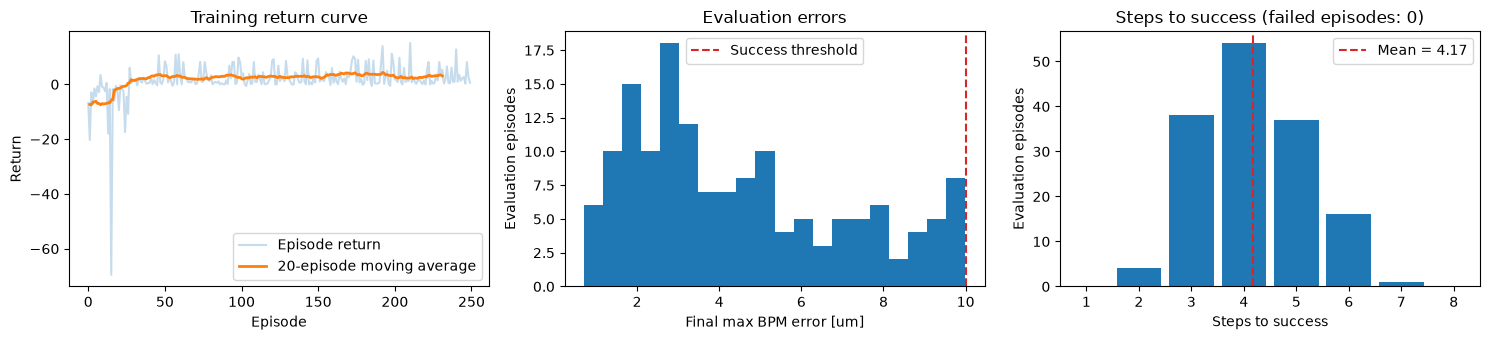

In [10]:
def moving_average(values: list[float], window: int = 20) -> np.ndarray:
    """Return trailing moving average."""
    if len(values) < 1:
        return np.asarray([], dtype=np.float64)
    window_size = min(window, len(values))
    kernel = np.ones(window_size, dtype=np.float64) / window_size
    return np.convolve(np.asarray(values, dtype=np.float64), kernel, mode="valid")


smoothed_returns = moving_average(episode_returns, window=20)
success_mask = np.asarray(evaluation_successes, dtype=bool)
steps_to_success = np.asarray(evaluation_lengths, dtype=np.int64)[success_mask]
failed_episode_count = int(np.count_nonzero(~success_mask))
step_bin_edges = np.arange(0.5, MAX_STEPS + 1.5, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(episode_returns, alpha=0.25, label="Episode return")
axes[0].plot(
    np.arange(len(smoothed_returns)) + 1,
    smoothed_returns,
    linewidth=2.0,
    label="20-episode moving average",
)
axes[0].set(xlabel="Episode", ylabel="Return", title="Training return curve")
axes[0].legend()
axes[1].hist(1.0e6 * np.asarray(final_max_errors), bins=20)
axes[1].axvline(1.0e6 * TARGET_TOLERANCE, color="tab:red", linestyle="--", label="Success threshold")
axes[1].set(xlabel="Final max BPM error [um]", ylabel="Evaluation episodes", title="Evaluation errors")
axes[1].legend()
axes[2].hist(steps_to_success, bins=step_bin_edges, rwidth=0.85)
if steps_to_success.size > 0:
    axes[2].axvline(
        np.mean(steps_to_success),
        color="tab:red",
        linestyle="--",
        label=f"Mean = {np.mean(steps_to_success):.2f}",
    )
    axes[2].set_xlim(0.5, steps_to_success.max() + 1.5)
    axes[2].legend()
axes[2].set(
    xlabel="Steps to success",
    ylabel="Evaluation episodes",
    title=f"Steps to success (failed episodes: {failed_episode_count})",
)
fig.tight_layout()

### 7.3 Before/after trajectory on one held-out episode

The policy observes current BPM values, BPM differences, previous action, and current normalized kicks at each step.
The full trajectory is shown only for visualization; the agent never sees the orbit between the BPMs.

Physics check: zeroing both BPMs means $x = x' = 0$ on the drift between them. Since there is no element after C2
other than drifts, the orbit is zero all the way from C2 to BPM2. Upstream of C2 the orbit stays nonzero, because
two BPMs can only constrain the beam downstream of the last corrector. Whether this particular episode reaches the
10 µm target depends on the trained policy; compare the printed final readings with the threshold.

Final BPM readings after SAC [um]: [2.44354097 3.61598986]


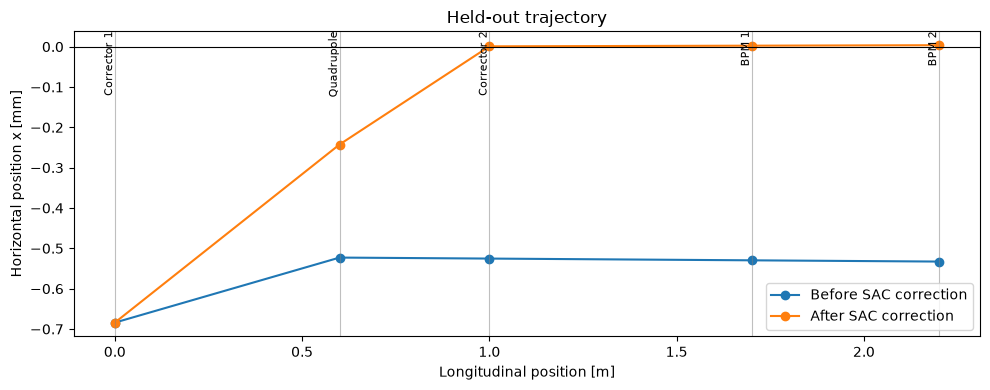

In [11]:
trajectory_env = TwoCorrectorOrbitEnv(LATTICE, rng_seed=20_026)
state = trajectory_env.reset()
positions, orbit_before = trajectory_env.simulator.trajectory(trajectory_env.kicks)
done = False
while not done:
    action = policy.deterministic_action(state)
    state, _, done, _ = trajectory_env.step(action)
_, orbit_after = trajectory_env.simulator.trajectory(trajectory_env.kicks)

element_positions = positions
element_names = ["Corrector 1", "Quadrupole", "Corrector 2", "BPM 1", "BPM 2"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(positions, 1.0e3 * orbit_before, marker="o", label="Before SAC correction")
ax.plot(positions, 1.0e3 * orbit_after, marker="o", label="After SAC correction")
for element_position, element_name in zip(element_positions, element_names):
    ax.axvline(element_position, color="gray", linewidth=0.8, alpha=0.5)
    ax.text(element_position, ax.get_ylim()[1], element_name, rotation=90, va="top", ha="right", fontsize=8)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set(xlabel="Longitudinal position [m]", ylabel="Horizontal position x [mm]", title="Held-out trajectory")
ax.legend()
fig.tight_layout()
print("Final BPM readings after SAC [um]:", 1.0e6 * orbit_after[-2:])

## 8. Discussion and limitations

**RL versus the response-matrix method.** In this linear, noiseless model, the response-matrix correction is exact
after a few probe measurements, while the RL agent needs thousands of interaction steps and converges over several
steps. RL becomes attractive when the system is nonlinear,
noisy, or drifting, when constraints matter, or when measuring the response is costly. Even then, data efficiency and
machine safety are major concerns: agents are usually trained in simulation and then transferred to the real machine
(*sim-to-real*), often combined with model-based methods.

**What the RL fine-tuning achieves here.** With the current settings the fine-tuning is *stable*: the success rate
stays at 100% throughout training. It does not, however, make correction faster than the warm-start policy (about
4.2 steps per episode, against about 2.2 for the exact correction). The candidate policies typically need 5 to 5.5
steps, so checkpoint selection usually keeps the warm-start policy or one from early in training. Closing this gap
requires a critic that can represent how the best action depends on the hidden $k$, which the BPM differences and
previous action reveal. Our quadratic features do not contain such products.

**Implementation limitations.**

- This is a compact educational implementation, not a full industrial SAC stack.
- Actor update uses critic action gradients through a tanh-squashed Gaussian policy, with fixed exploration noise
  and no entropy term in the actor gradient (Section 5.2).
- Critics are linear in engineered features; this keeps dependencies minimal but limits how well $Q$ can be represented.
- Reaching the time limit sets `done = True` in the same way as success, so the critic treats a time-out as a true
  terminal state. Proper implementations distinguish *termination* from *truncation*
  (Gymnasium's `terminated` / `truncated` flags) and keep bootstrapping on truncation.
- Results come from a single training run with checkpoint selection; training variability is not quantified.

**Model limitations.**

- The machine model is linear, noiseless, and horizontal-only.
- For more realism, add noise, calibration drift, constraints, and temporal history.

## Exercises

1. **Effect of the warm start.** Set `%env ORACLE_WARMSTART_SAMPLES=0` and rerun. How do learning speed and final
   success rate change?
2. **Training variability.** Rerun the notebook with several `SEED` values and report the mean and spread of the
   final success rate. Compare with the spread of the five-seed evaluation in Section 7.1.
3. **Observation design.** Remove the BPM differences and previous action from the observation. Does performance
   drop, as the partial-observability argument in Section 3 suggests?
4. **Reward design.** Remove the milestone bonuses or the progress term. What happens to learning?
5. **Measurement noise.** Add Gaussian BPM noise of a few micrometres in `bpm_readings`. How do the RL agent and the
   response-matrix baseline degrade? (Hint: the 1 µrad probe of the baseline becomes too small.)
6. **Toward full SAC.** Make $\log\sigma$ learnable and add the entropy term to the actor gradient. Does the
   automatic $\alpha$ tuning then behave as intended?